# Predicting the Severity of Road Traffic Accidents: Tuning, Balancing and Final Evaluation
**ARTI 205 Machine Learning | Group 3**

This notebook finishes steps 6 to 8 of our methodology:

1. **Tune** four models with grid search and 5-fold stratified cross-validation (Week 3 and Week 8).
2. **Compare balancing methods** on the training data only: no balancing, class weights (cost-sensitive learning), random under-sampling and SMOTE-NC (Week 8).
3. **Test feature selection** by removing redundant attributes (Week 6).
4. **Evaluate** every model once on the untouched test set, with per-class recall, macro F1 and confusion matrices.
5. **Explain** the final model with SHAP.

Input: `../Data/UK_collisions_final.csv` (made by notebook 01). The split is the same as in notebook 02.
Running the whole notebook takes about 1 to 1.5 hours on a normal laptop (most of the time goes to Random Forest, SMOTE-NC and SHAP).

In [1]:
import time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, classification_report, make_scorer)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline            # like sklearn's Pipeline, but it also accepts samplers
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC
import shap
warnings.filterwarnings("ignore")

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
SEED = 42
def log(msg):                                     # progress note, useful because some steps take minutes
    line = f"{time.strftime('%H:%M:%S')}  {msg}"
    print(line, flush=True)
    with open(RES / "progress.log", "a") as f: f.write(line + "\n")

BLUE, ORANGE, AQUA, YELLOW, GREY, INK, MUTED, GRIDC = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9aa3ae", "#1b2430", "#4a5568", "#e4e6ea"
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({"font.family": "Inter" if "Inter" in fonts else "DejaVu Sans", "font.size": 12,
                     "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRIDC, "axes.axisbelow": True,
                     "axes.edgecolor": GRIDC, "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED})

## 1. Data, split and encoding (same as notebook 02)

In [2]:
df = pd.read_csv("../Data/UK_collisions_final.csv")
assert df.isna().sum().sum() == 0
NUM = ["hour", "month", "speed_limit", "number_of_vehicles", "speed_x_vehicles", "speed_per_vehicle"]
CAT = [c for c in df.columns if c not in NUM + ["severity"]]
CLASSES = ["Slight", "Serious", "Fatal"]
y = df["severity"].map({c: i for i, c in enumerate(CLASSES)})
X = df.drop(columns="severity")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(X_tr):,} | test {len(X_te):,} | fatal: train {(y_tr == 2).sum()}, test {(y_te == 2).sum()}")

def make_prep(cat=CAT, num=NUM):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])
CAT_IDX = [X.columns.get_loc(c) for c in CAT]     # SMOTE-NC must know which raw columns are categorical
W_TR = compute_sample_weight("balanced", y_tr)    # class weights as sample weights (for XGBoost)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"macro_f1": "f1_macro", "balanced_acc": "balanced_accuracy",
           "fatal_recall": make_scorer(recall_score, labels=[2], average="macro"),
           "serious_recall": make_scorer(recall_score, labels=[1], average="macro"),
           "slight_recall": make_scorer(recall_score, labels=[0], average="macro")}
print("one-hot + numeric columns after encoding:", make_prep().fit(X_tr).transform(X_tr[:5]).shape[1])

train 80,741 | test 20,186 | fatal: train 1202, test 300


one-hot + numeric columns after encoding: 351


## 2. Step 1: Hyperparameter tuning (grid search, 5-fold CV)
Every candidate is scored by **macro F1** on the 5 validation folds of the **training set only**; the test set is not touched.
During tuning all models use **class weights** (cost-sensitive learning), so the rare classes count more.
Random Forest uses 200 trees here to keep the search fast; the final model uses 300.

In [3]:
def model(name, **kw):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=3000, class_weight="balanced", **kw)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=kw.pop("n_estimators", 200), class_weight="balanced",
                                      max_features="sqrt", n_jobs=-1, random_state=SEED, **kw)
    if name == "XGBoost":
        return XGBClassifier(tree_method="hist", subsample=0.9, colsample_bytree=0.8, n_jobs=-1, random_state=SEED, **kw)
    if name == "Decision Tree":
        return DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **kw)

GRIDS = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__max_depth": [12, 20, None], "model__min_samples_leaf": [5, 20]},
    "XGBoost": {"model__n_estimators": [300, 600], "model__max_depth": [4, 6], "model__learning_rate": [0.05, 0.1]},
    "Decision Tree": {"model__max_depth": [8, 12, 20, None], "model__min_samples_leaf": [5, 20, 50]},
}
NEEDS_WEIGHTS = {"XGBoost"}    # no class_weight option -> pass sample weights

best_params, tuning_rows = {}, []
for name, grid in GRIDS.items():
    t = time.time()
    pipe = Pipeline([("prep", make_prep()), ("model", model(name))])
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=CV, refit=False,
                      n_jobs=1 if name in ("Random Forest", "XGBoost") else 2)
    gs.fit(X_tr, y_tr, **({"model__sample_weight": W_TR} if name in NEEDS_WEIGHTS else {}))
    cvr = pd.DataFrame(gs.cv_results_)
    cvr.to_csv(RES / f"grid_{name.split(' ')[0].lower()}.csv", index=False)
    best_params[name] = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    tuning_rows.append({"model": name, "best parameters": best_params[name],
                        "CV macro F1": gs.best_score_, "std": cvr.loc[gs.best_index_, "std_test_score"],
                        "candidates": len(cvr), "minutes": round((time.time() - t) / 60, 1)})
    log(f"tuned {name}: {best_params[name]}  CV macro F1 {gs.best_score_:.3f}")
tuning = pd.DataFrame(tuning_rows).set_index("model")
tuning.to_csv(RES / "tuning_summary.csv")
json.dump({k: {p: (list(v) if isinstance(v, tuple) else v) for p, v in d.items()} for k, d in best_params.items()},
          open(RES / "best_params.json", "w"), indent=2)
tuning.round(3)

21:51:26  tuned Logistic Regression: {'C': 0.01}  CV macro F1 0.372


21:54:00  tuned Random Forest: {'max_depth': None, 'min_samples_leaf': 5}  CV macro F1 0.439


21:56:00  tuned XGBoost: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 600}  CV macro F1 0.416


21:58:13  tuned Decision Tree: {'max_depth': None, 'min_samples_leaf': 5}  CV macro F1 0.373


,best parameters,CV macro F1,std,candidates,minutes
model,,,,,
Logistic Regression,{'C': 0.01},0.372,0.003,4,0.7
Random Forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.439,0.003,6,2.6
XGBoost,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.416,0.003,8,2.0
Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5}",0.373,0.002,12,2.2


## 3. Step 2: Which balancing method works best? (5-fold CV, training data only)
The sampler sits **inside** the pipeline, so in each fold only the training part is re-sampled and the validation part keeps the real class shares.

| Method | What it does |
|---|---|
| None | train on the data as it is |
| Class weights | cost-sensitive learning: mistakes on rare classes cost more |
| Under-sampling | randomly drop Slight and Serious rows until all classes are equal |
| SMOTE-NC | create synthetic Serious and Fatal rows (SMOTE for data with categorical columns) |

In [4]:
def tuned(name, weighted):
    p = dict(best_params[name])
    if "hidden_layer_sizes" in p: p["hidden_layer_sizes"] = tuple(p["hidden_layer_sizes"])
    m = model(name, **p)
    if not weighted and name in ("Logistic Regression", "Decision Tree", "Random Forest"):
        m.set_params(class_weight=None)
    return m

STRATEGIES = ["None", "Class weights", "Under-sampling", "SMOTE-NC"]
def build(name, strategy):
    steps = []
    if strategy == "Under-sampling": steps.append(("sampler", RandomUnderSampler(random_state=SEED)))
    if strategy == "SMOTE-NC": steps.append(("sampler", SMOTENC(categorical_features=CAT_IDX, random_state=SEED)))
    steps += [("prep", make_prep()), ("model", tuned(name, weighted=(strategy == "Class weights")))]
    return Pipeline(steps)

bal_rows = []
for name in GRIDS:
    for strategy in STRATEGIES:
        t = time.time()
        params = {"model__sample_weight": W_TR} if (strategy == "Class weights" and name in NEEDS_WEIGHTS) else {}
        cv = cross_validate(build(name, strategy), X_tr, y_tr, cv=CV, scoring=SCORING, params=params, n_jobs=1)
        row = {"model": name, "strategy": strategy, "minutes": round((time.time() - t) / 60, 1)}
        for k in SCORING:
            row[k] = cv[f"test_{k}"].mean()
        row["macro_f1_std"] = cv["test_macro_f1"].std()
        bal_rows.append(row)
        log(f"{name:22s} {strategy:15s} macro F1 {row['macro_f1']:.3f}  fatal recall {row['fatal_recall']:.3f}")
balance = pd.DataFrame(bal_rows)
balance.to_csv(RES / "balancing_cv.csv", index=False)
balance.pivot(index="model", columns="strategy", values="macro_f1")[STRATEGIES].round(3)

21:58:21  Logistic Regression    None            macro F1 0.331  fatal recall 0.000


21:58:33  Logistic Regression    Class weights   macro F1 0.372  fatal recall 0.657


21:58:34  Logistic Regression    Under-sampling  macro F1 0.356  fatal recall 0.662


22:00:33  Logistic Regression    SMOTE-NC        macro F1 0.390  fatal recall 0.363


22:01:18  Random Forest          None            macro F1 0.325  fatal recall 0.000


22:02:01  Random Forest          Class weights   macro F1 0.439  fatal recall 0.188


... (7 outputs left out)

22:10:13  Decision Tree          Class weights   macro F1 0.373  fatal recall 0.152


22:10:13  Decision Tree          Under-sampling  macro F1 0.322  fatal recall 0.482


22:13:23  Decision Tree          SMOTE-NC        macro F1 0.379  fatal recall 0.103


strategy,None,Class weights,Under-sampling,SMOTE-NC
model,,,,
Decision Tree,0.374,0.373,0.322,0.379
Logistic Regression,0.331,0.372,0.356,0.390
Random Forest,0.325,0.439,0.349,0.415
XGBoost,0.361,0.416,0.348,0.409


In [5]:
balance.pivot(index="model", columns="strategy", values="fatal_recall")[STRATEGIES].round(3)

strategy,None,Class weights,Under-sampling,SMOTE-NC
model,,,,
Decision Tree,0.022,0.152,0.482,0.103
Logistic Regression,0.000,0.657,0.662,0.363
Random Forest,0.000,0.188,0.682,0.173
XGBoost,0.017,0.287,0.617,0.168


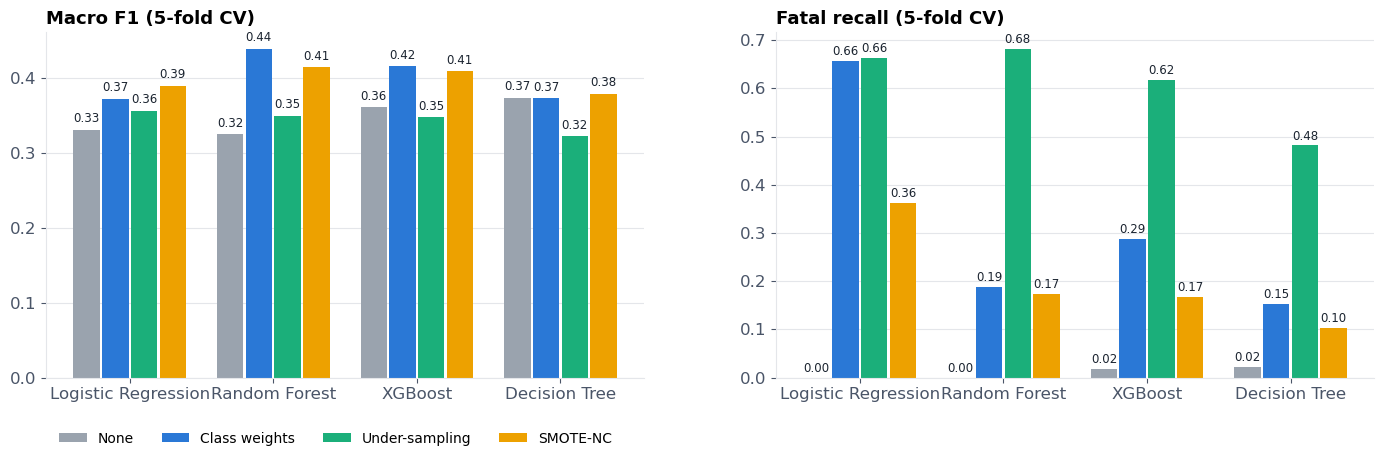

In [6]:
# chart: macro F1 and fatal recall for every model and balancing method
cols = {"None": GREY, "Class weights": BLUE, "Under-sampling": AQUA, "SMOTE-NC": YELLOW}
models_order = list(GRIDS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, title in [(axes[0], "macro_f1", "Macro F1 (5-fold CV)"), (axes[1], "fatal_recall", "Fatal recall (5-fold CV)")]:
    xs = np.arange(len(models_order)); wbar = 0.2
    for k, s in enumerate(STRATEGIES):
        vals = [balance[(balance["model"] == m) & (balance["strategy"] == s)][metric].iloc[0] for m in models_order]
        bars = ax.bar(xs + (k - 1.5) * wbar, vals, width=wbar * 0.92, color=cols[s], label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_xticks(xs); ax.set_xticklabels(models_order)
    ax.set_title(title, loc="left"); ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left", ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0, -0.12))
fig.tight_layout()
fig.savefig(FIG / "09_balancing_comparison.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 4. Choose each model's best setting
For every model we keep the balancing method with the **highest CV macro F1**. The final model is the one with the highest CV macro F1 overall, chosen **before** looking at the test set.

In [7]:
best_strategy = balance.loc[balance.groupby("model")["macro_f1"].idxmax()].set_index("model")
best_strategy = best_strategy.loc[models_order]
FINAL = best_strategy["macro_f1"].idxmax()
print("best balancing method per model:")
print(best_strategy[["strategy", "macro_f1", "fatal_recall"]].round(3))
print("\nfinal model (highest CV macro F1):", FINAL, "with", best_strategy.loc[FINAL, "strategy"])

best balancing method per model:
                          strategy  macro_f1  fatal_recall
model                                                     
Logistic Regression       SMOTE-NC     0.390         0.363
Random Forest        Class weights     0.439         0.188
XGBoost              Class weights     0.416         0.287
Decision Tree             SMOTE-NC     0.379         0.103

final model (highest CV macro F1): Random Forest with Class weights


## 5. Step 3: Feature selection test (filter method, Week 6)
Notebook 01 showed that some attributes repeat the same information (Cramér's V heatmap):
`junction_control` and `second_road_class` repeat `junction_detail`, and `road_surface_conditions` repeats `weather_conditions`.
We remove these three and check the final model again with 5-fold CV.

In [8]:
DROP = ["junction_control", "second_road_class", "road_surface_conditions"]
keep_cols = [c for c in X.columns if c not in DROP]
cat_small = [c for c in CAT if c not in DROP]
s = best_strategy.loc[FINAL, "strategy"]
steps = []
if s == "Under-sampling": steps.append(("sampler", RandomUnderSampler(random_state=SEED)))
if s == "SMOTE-NC": steps.append(("sampler", SMOTENC(categorical_features=[keep_cols.index(c) for c in cat_small], random_state=SEED)))
steps += [("prep", make_prep(cat_small, NUM)), ("model", tuned(FINAL, weighted=(s == "Class weights")))]
params = {"model__sample_weight": W_TR} if (s == "Class weights" and FINAL in NEEDS_WEIGHTS) else {}
t = time.time()
cv_fs = cross_validate(Pipeline(steps), X_tr[keep_cols], y_tr, cv=CV, scoring=SCORING, params=params)
fs = pd.DataFrame({"all 31 features": best_strategy.loc[FINAL, ["macro_f1", "fatal_recall", "balanced_acc"]].values.astype(float),
                   "28 features (3 removed)": [cv_fs["test_macro_f1"].mean(), cv_fs["test_fatal_recall"].mean(),
                                               cv_fs["test_balanced_acc"].mean()]},
                  index=["CV macro F1", "CV fatal recall", "CV balanced accuracy"])
fs.to_csv(RES / "feature_selection.csv")
log(f"feature selection test done in {(time.time() - t) / 60:.1f} min")
fs.round(3)

22:14:03  feature selection test done in 0.7 min


,all 31 features,28 features (3 removed)
CV macro F1,0.439,0.439
CV fatal recall,0.188,0.219
CV balanced accuracy,0.461,0.469


In [9]:
USE_SMALL = fs.loc["CV macro F1", "28 features (3 removed)"] > fs.loc["CV macro F1", "all 31 features"] + 0.002
print("keep the 28-feature version" if USE_SMALL else "keep all 31 features (removing them does not help)")

keep all 31 features (removing them does not help)


## 6. Step 4: Final evaluation on the test set
Each model is trained once on the **whole training set** with its tuned parameters and best balancing method,
then tested **once** on the 20,186 test collisions (300 fatal). Random Forest now uses 300 trees.

In [10]:
def final_pipe(name, strategy, cols=list(X.columns), cat=CAT):
    steps = []
    if strategy == "Under-sampling": steps.append(("sampler", RandomUnderSampler(random_state=SEED)))
    if strategy == "SMOTE-NC": steps.append(("sampler", SMOTENC(categorical_features=[cols.index(c) for c in cat], random_state=SEED)))
    m = tuned(name, weighted=(strategy == "Class weights"))
    if name == "Random Forest": m.set_params(n_estimators=300)
    steps += [("prep", make_prep(cat, NUM)), ("model", m)]
    return Pipeline(steps)

def scores(y_true, pred, proba=None):
    r = recall_score(y_true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    p = precision_score(y_true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"accuracy": accuracy_score(y_true, pred), "balanced accuracy": balanced_accuracy_score(y_true, pred),
            "macro F1": f1_score(y_true, pred, average="macro"), "recall Slight": r[0], "recall Serious": r[1],
            "recall Fatal": r[2], "precision Fatal": p[2],
            "AUC (macro, one-vs-rest)": roc_auc_score(y_true, proba, multi_class="ovr", average="macro") if proba is not None else np.nan}

test_rows, fitted, preds = [], {}, {}
dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
test_rows.append({"model": "Always 'Slight' (no model)", "balancing": "-", **scores(y_te, dummy.predict(X_te))})
for name in models_order:
    s = best_strategy.loc[name, "strategy"]
    small = USE_SMALL and name == FINAL
    cols, cat = (keep_cols, cat_small) if small else (list(X.columns), CAT)
    pipe = final_pipe(name, s, cols, cat)
    t = time.time()
    fit_params = {"model__sample_weight": W_TR} if (s == "Class weights" and name in NEEDS_WEIGHTS) else {}
    pipe.fit(X_tr[cols], y_tr, **fit_params)
    fitted[name] = (pipe, cols)
    preds[name] = pipe.predict(X_te[cols])
    test_rows.append({"model": name, "balancing": s, **scores(y_te, preds[name], pipe.predict_proba(X_te[cols]))})
    log(f"test {name}: macro F1 {test_rows[-1]['macro F1']:.3f}  fatal recall {test_rows[-1]['recall Fatal']:.3f}  ({(time.time() - t) / 60:.1f} min)")
test_res = pd.DataFrame(test_rows).set_index("model")
test_res.to_csv(RES / "test_results.csv")
test_res.round(3)

22:14:37  test Logistic Regression: macro F1 0.389  fatal recall 0.380  (0.6 min)


22:14:54  test Random Forest: macro F1 0.435  fatal recall 0.187  (0.3 min)


22:14:58  test XGBoost: macro F1 0.406  fatal recall 0.277  (0.1 min)


22:15:53  test Decision Tree: macro F1 0.380  fatal recall 0.107  (0.9 min)


,balancing,accuracy,balanced accuracy,macro F1,recall Slight,recall Serious,recall Fatal,precision Fatal,"AUC (macro, one-vs-rest)"
model,,,,,,,,,
Always 'Slight' (no model),-,0.752,0.333,0.286,1.000,0.000,0.000,0.000,NaN
Logistic Regression,SMOTE-NC,0.599,0.472,0.389,0.678,0.359,0.380,0.051,0.672
Random Forest,Class weights,0.669,0.458,0.435,0.751,0.436,0.187,0.094,0.714
XGBoost,Class weights,0.604,0.472,0.406,0.646,0.492,0.277,0.053,0.706
Decision Tree,SMOTE-NC,0.622,0.394,0.380,0.712,0.364,0.107,0.050,0.581


In [11]:
print(f"FINAL MODEL: {FINAL} ({best_strategy.loc[FINAL, 'strategy']})\n")
print(classification_report(y_te, preds[FINAL], target_names=CLASSES, digits=3))

FINAL MODEL: Random Forest (Class weights)

              precision    recall  f1-score   support

      Slight      0.818     0.751     0.783     15172
     Serious      0.363     0.436     0.396      4714
       Fatal      0.094     0.187     0.125       300

    accuracy                          0.669     20186
   macro avg      0.425     0.458     0.435     20186
weighted avg      0.701     0.669     0.683     20186



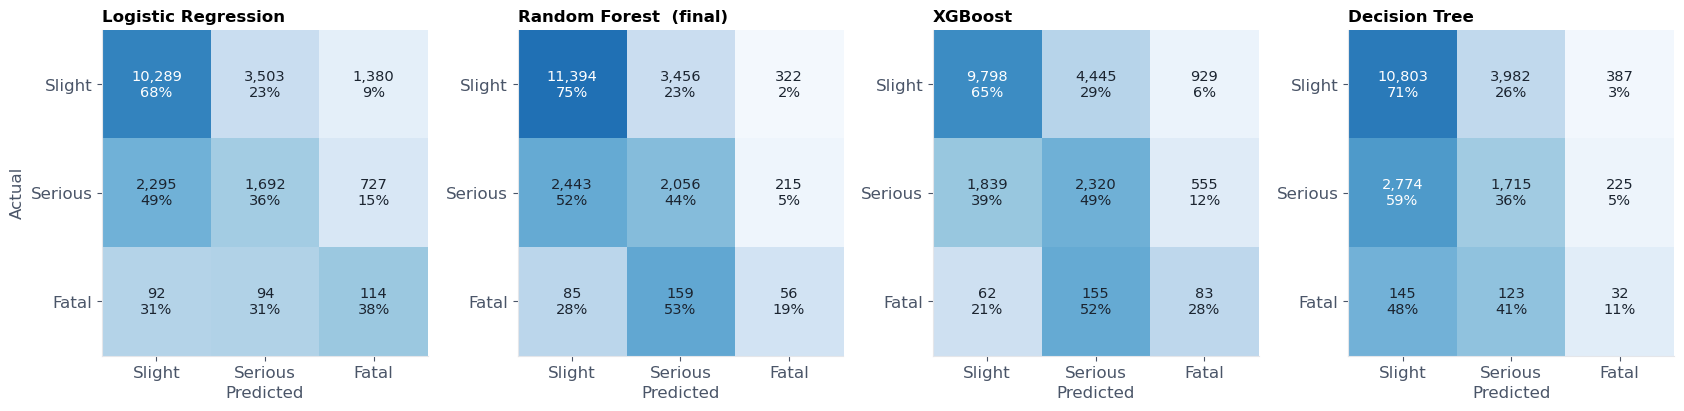

In [12]:
# confusion matrices of the four models (rows = actual, columns = predicted, % of each actual class)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, name in zip(axes, models_order):
    cm = confusion_matrix(y_te, preds[name], labels=[0, 1, 2])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.0%}", ha="center", va="center", fontsize=10.5,
                    color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
    ax.grid(False); ax.set_xlabel("Predicted")
    ax.set_title(name + ("  (final)" if name == FINAL else ""), loc="left", fontsize=12)
axes[0].set_ylabel("Actual")
fig.tight_layout()
fig.savefig(FIG / "10_confusion_matrices.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 7. Step 5: Explaining the final model with SHAP
SHAP gives each feature a share of every single prediction. We explain the **Fatal** class on a sample of test collisions where one quarter are fatal, so the rare class is well represented
(up to 600 rows, scaled to keep SHAP runtime practical). We add up the one-hot columns of each attribute
so the chart shows the 31 model attributes.

22:16:07  SHAP: 1.39 s per row -> explaining 516 test collisions


22:28:05  SHAP for Random Forest done in 12.0 min


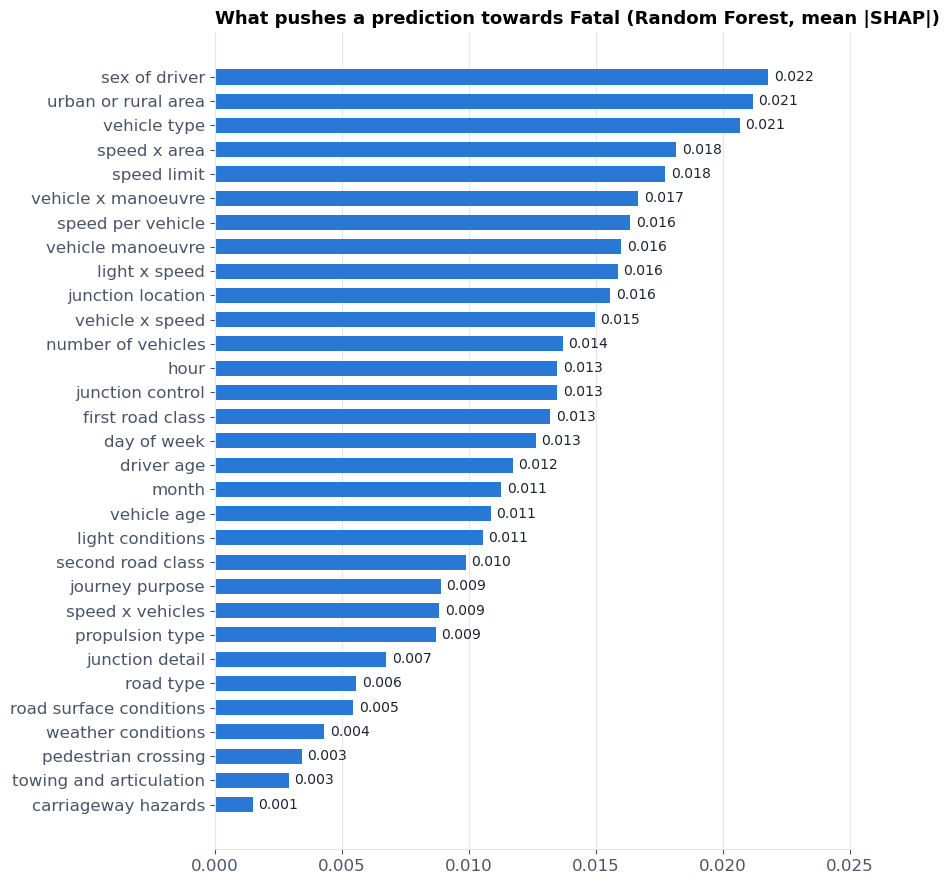

sex_of_driver          0.0218
urban_or_rural_area    0.0212
vehicle_type           0.0207
speed_x_area           0.0182
speed_limit            0.0177
vehicle_x_manoeuvre    0.0167
speed_per_vehicle      0.0163
vehicle_manoeuvre      0.0160
light_x_speed          0.0159
junction_location      0.0156
dtype: float64

In [13]:
tree_models = [m for m in models_order if m in ("Random Forest", "XGBoost")]
EXPL = FINAL if FINAL in tree_models else max(tree_models, key=lambda m: test_res.loc[m, "macro F1"])
pipe, cols = fitted[EXPL]
prep_f, mdl = pipe.named_steps["prep"], pipe.named_steps["model"]
rng = np.random.RandomState(SEED)
idx_fatal = np.where(y_te.values == 2)[0]
idx_other = rng.choice(np.where(y_te.values != 2)[0], 600 - min(150, len(idx_fatal)), replace=False)
idx = np.concatenate([rng.choice(idx_fatal, min(150, len(idx_fatal)), replace=False), idx_other])
Xs = prep_f.transform(X_te[cols].iloc[idx])
Xs = Xs.toarray() if hasattr(Xs, "toarray") else Xs
names = list(prep_f.get_feature_names_out())
explainer = shap.TreeExplainer(mdl)
t = time.time(); explainer.shap_values(Xs[:10], check_additivity=False)
per_row = (time.time() - t) / 10                       # big forests are slow to explain: keep it under ~12 minutes
n_rows = int(np.clip(720 / max(per_row, 1e-3), 150, 600))
if n_rows < len(Xs):                                   # keep the same fatal share when the sample is cut
    keep = np.r_[0:int(n_rows / 4), 150:150 + n_rows - int(n_rows / 4)]
    Xs, idx = Xs[keep], idx[keep]
log(f"SHAP: {per_row:.2f} s per row -> explaining {len(Xs)} test collisions")
t = time.time()
sv = explainer.shap_values(Xs, check_additivity=False)
sv_fatal = sv[:, :, 2] if np.ndim(sv) == 3 else sv[2]
log(f"SHAP for {EXPL} done in {(time.time() - t) / 60:.1f} min")

# add the one-hot columns back into their original attribute
def attr(n):
    n = n.split("__", 1)[1]
    for c in sorted(cols, key=len, reverse=True):
        if n == c or n.startswith(c + "_"): return c
    return n
groups = pd.Series([attr(n) for n in names])
agg = pd.DataFrame(sv_fatal, columns=names).T.groupby(groups.values).sum().T
imp = agg.abs().mean().sort_values()
imp.sort_values(ascending=False).to_csv(RES / "shap_fatal_importance.csv", header=["mean |SHAP| (Fatal)"])
fig, ax = plt.subplots(figsize=(9, 9.0))
ax.barh(imp.index.str.replace("_", " "), imp.values, color=BLUE, height=0.62)
for i, v in enumerate(imp.values): ax.text(v + imp.max() * 0.01, i, f"{v:.3f}", va="center", fontsize=10, color=INK)
ax.set_title(f"What pushes a prediction towards Fatal ({EXPL}, mean |SHAP|)", loc="left"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, imp.max() * 1.15)
fig.tight_layout(); fig.savefig(FIG / "11_shap_fatal_importance.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()
imp.sort_values(ascending=False).round(4).head(10)

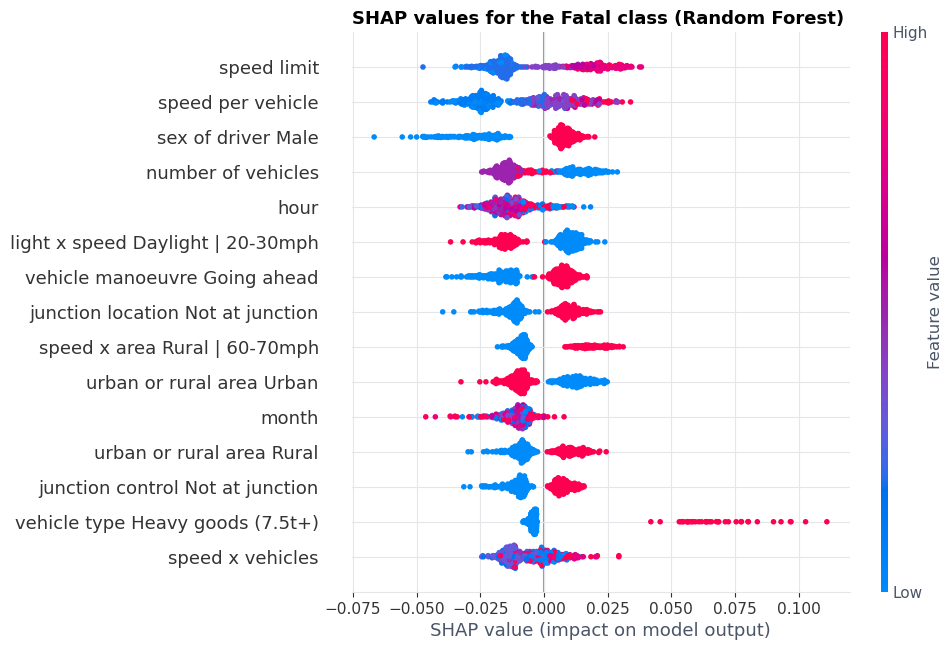

In [14]:
# direction of the effect for the 15 strongest one-hot columns (red = value present / high, blue = absent / low)
plt.figure()
shap.summary_plot(sv_fatal, Xs, feature_names=[n.split("__", 1)[1].replace("_", " ") for n in names],
                  max_display=15, show=False, plot_size=(10, 6.5))
plt.title(f"SHAP values for the Fatal class ({EXPL})", loc="left", fontsize=13)
plt.savefig(FIG / "12_shap_fatal_beeswarm.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 8. Summary of all results

In [15]:
import joblib
pipe_final, cols_final = fitted[FINAL]
joblib.dump({"pipeline": pipe_final, "columns": cols_final, "classes": CLASSES}, RES / "final_model.joblib", compress=("xz", 3))
log("saved final_model.joblib")
summary = {
    "final_model": FINAL, "final_balancing": best_strategy.loc[FINAL, "strategy"],
    "final_uses_28_features": bool(USE_SMALL), "explained_model": EXPL,
    "best_params": best_params,
    "test": test_res.round(4).reset_index().to_dict(orient="records"),
}
json.dump(summary, open(RES / "summary.json", "w"), indent=2, default=str)
log("notebook finished")
test_res[["balancing", "accuracy", "balanced accuracy", "macro F1", "recall Slight", "recall Serious", "recall Fatal", "precision Fatal", "AUC (macro, one-vs-rest)"]].round(3)

22:28:06  saved final_model.joblib


22:28:06  notebook finished


,balancing,accuracy,balanced accuracy,macro F1,recall Slight,recall Serious,recall Fatal,precision Fatal,"AUC (macro, one-vs-rest)"
model,,,,,,,,,
Always 'Slight' (no model),-,0.752,0.333,0.286,1.000,0.000,0.000,0.000,NaN
Logistic Regression,SMOTE-NC,0.599,0.472,0.389,0.678,0.359,0.380,0.051,0.672
Random Forest,Class weights,0.669,0.458,0.435,0.751,0.436,0.187,0.094,0.714
XGBoost,Class weights,0.604,0.472,0.406,0.646,0.492,0.277,0.053,0.706
Decision Tree,SMOTE-NC,0.622,0.394,0.380,0.712,0.364,0.107,0.050,0.581
